In [1]:
#imports
import matplotlib.pyplot as plt
import numpy as np

#task1 : 1. Trajectory Preprocessing

In [2]:
# importing the dataset

file_path = "uji+pen+characters+version+2/ujipenchars2.txt"

In [3]:
file_path = "uji+pen+characters+version+2/ujipenchars2.txt"

# Hierarchy: data[writer][char][repetition_idx] -> list of strokes -> list of (x, y)
data = {}

current_writer = None
current_char = None
current_strokes = None

f = open(file_path, "r", encoding="utf-8")

while True:
    line = f.readline()
    if not line:  # End of file reached
        break

    line = line.strip()
    if not line or line.startswith("//"):
        continue

    # 1. New character sample header: WORD <char> <writer_session_id>
    if line.startswith("WORD"):
        # Save previous sample if exists
        if current_writer and current_strokes:
            data[current_writer][current_char].append(current_strokes)

        _, char, session_id = line.split()
        writer_id, rep = session_id.split("-")  # e.g., 'trn_UJI_W01', '01'

        current_writer = writer_id
        current_char = char
        current_strokes = []

        if current_writer not in data:
            data[current_writer] = {}
        if current_char not in data[current_writer]:
            data[current_writer][current_char] = []

    # 2. Coordinates: POINTS <n> # x1 y1 x2 y2 ...
    elif line.startswith("POINTS"):
        coords = [float(x) for x in line.split("#")[1].split()]
        stroke = [(coords[i], coords[i+1]) for i in range(0, len(coords), 2)]
        current_strokes.append(stroke)

# Append the final sample in the file
if current_writer and current_strokes:
    data[current_writer][current_char].append(current_strokes)

f.close()

print(f"Total writers loaded: {len(data)}")
print(f"Characters for writer 'trn_UJI_W01': {len(data['trn_UJI_W01'])}")
print(f"Repetitions for 'a': {len(data['trn_UJI_W01']['a'])}")

Total writers loaded: 60
Characters for writer 'trn_UJI_W01': 97
Repetitions for 'a': 2


In [4]:
def count_repetitions(dataset, writer=None):
    counts = {}
    writers = [writer] if writer is not None else dataset

    for writer_id in writers:
        for char, repetitions in dataset[writer_id].items():
            counts[char] = counts.get(char, 0) + len(repetitions)

    return counts

In [5]:
# Total repetitions of each character across all writers
counts = count_repetitions(data)
for char, count in sorted(counts.items()):
    print(f"{char!r}: {count} repetitions")


'!': 120 repetitions
'"': 120 repetitions
'$': 120 repetitions
'%': 120 repetitions
"'": 120 repetitions
'(': 120 repetitions
')': 120 repetitions
',': 120 repetitions
'-': 120 repetitions
'.': 120 repetitions
'0': 120 repetitions
'1': 120 repetitions
'2': 120 repetitions
'3': 120 repetitions
'4': 120 repetitions
'5': 120 repetitions
'6': 120 repetitions
'7': 120 repetitions
'8': 120 repetitions
'9': 120 repetitions
':': 120 repetitions
';': 120 repetitions
'<': 120 repetitions
'>': 120 repetitions
'?': 120 repetitions
'@': 120 repetitions
'A': 120 repetitions
'B': 120 repetitions
'C': 120 repetitions
'D': 120 repetitions
'E': 120 repetitions
'F': 120 repetitions
'G': 120 repetitions
'H': 120 repetitions
'I': 120 repetitions
'J': 120 repetitions
'K': 120 repetitions
'L': 120 repetitions
'M': 120 repetitions
'N': 120 repetitions
'O': 120 repetitions
'P': 120 repetitions
'Q': 120 repetitions
'R': 120 repetitions
'S': 120 repetitions
'T': 120 repetitions
'U': 120 repetitions
'V': 120 repe

In [6]:
# Number of writers
print("Number of writers:", len(data))

# Number of unique characters across all writers
unique_chars = {char for chars in data.values() for char in chars}
print("Number of unique characters:", len(unique_chars))

# Number of characters for each writer
for writer, chars in data.items():
    print(f"{writer}: {len(chars)} characters")

Number of writers: 60
Number of unique characters: 97
trn_UJI_W01: 97 characters
trn_UJI_W02: 97 characters
trn_UJI_W03: 97 characters
trn_UJI_W04: 97 characters
trn_UJI_W05: 97 characters
trn_UJI_W06: 97 characters
trn_UJI_W07: 97 characters
trn_UJI_W08: 97 characters
trn_UJI_W09: 97 characters
trn_UJI_W10: 97 characters
trn_UJI_W11: 97 characters
tst_UJI_W12: 97 characters
tst_UJI_W13: 97 characters
tst_UJI_W14: 97 characters
tst_UJI_W15: 97 characters
tst_UJI_W16: 97 characters
trn_UPV_W17: 97 characters
tst_UPV_W18: 97 characters
trn_UPV_W19: 97 characters
trn_UPV_W20: 97 characters
tst_UPV_W21: 97 characters
trn_UPV_W22: 97 characters
trn_UPV_W23: 97 characters
tst_UPV_W24: 97 characters
trn_UPV_W25: 97 characters
trn_UPV_W26: 97 characters
tst_UPV_W27: 97 characters
trn_UPV_W28: 97 characters
trn_UPV_W29: 97 characters
tst_UPV_W30: 97 characters
trn_UPV_W31: 97 characters
trn_UPV_W32: 97 characters
tst_UPV_W33: 97 characters
trn_UPV_W34: 97 characters
trn_UPV_W35: 97 characters
t

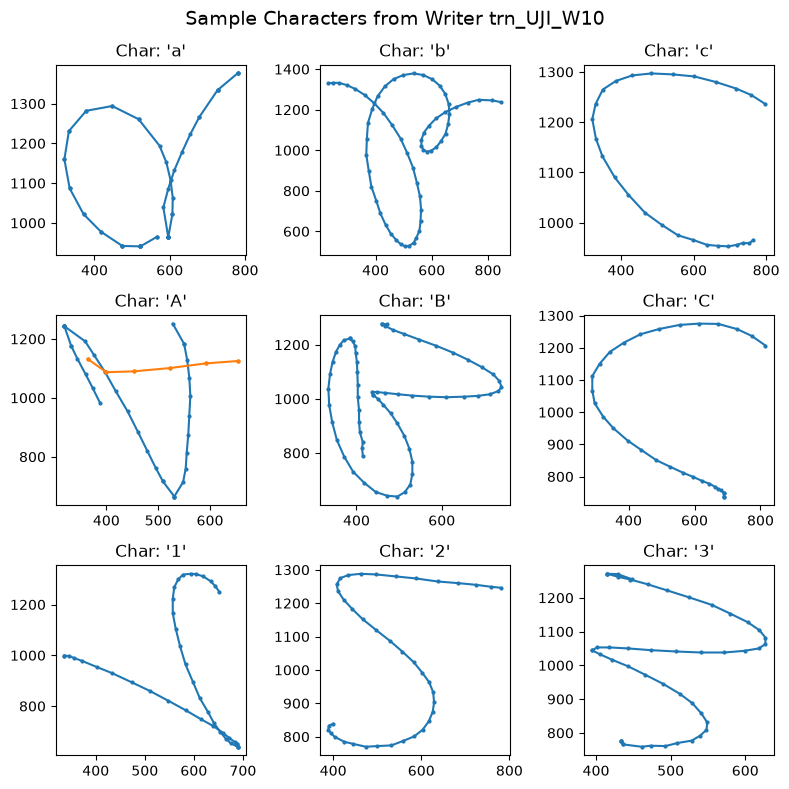

In [7]:
characters = ['a', 'b', 'c', 'A', 'B', 'C', '1', '2', '3']
writer = "trn_UJI_W10"

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for ax, char in zip(axes.flat, characters):
    strokes = data[writer][char][0]  # First repetition
    
    for stroke in strokes:
        xs = [p[0] for p in stroke]
        ys = [p[1] for p in stroke]
        ax.plot(xs, ys, "-o", markersize=2)
        
        ax.set_title(f"Char: '{char}'")

plt.suptitle(f"Sample Characters from Writer {writer}", fontsize=14)
plt.tight_layout()
plt.show()

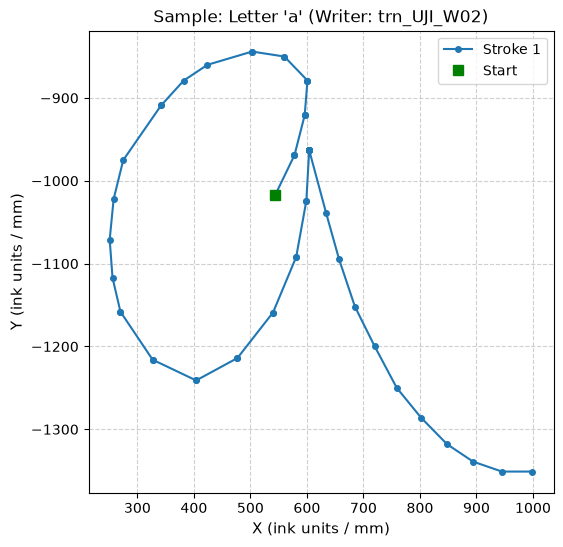

In [8]:
# 1. Pick a sample to plot (e.g., letter 'a' from writer 'trn_UJI_W01', repetition 0)
writer_id = "trn_UJI_W02"
sample_strokes = data[writer_id]["a"][0]
# 2. Create the plot with axes
fig = plt.figure(figsize=(6, 6))
for i, stroke in enumerate(sample_strokes):
    xs = [p[0] for p in stroke]
    ys = [-p[1] for p in stroke]
    
    # Plot the stroke path
    plt.plot(xs, ys, "-o", markersize=4, label=f"Stroke {i+1}")
    # Mark the starting point of the stroke
    plt.plot(xs[0], ys[0], "gs", markersize=7, label="Start" if i == 0 else "")
# 3. Add axes labels, title, and grid
plt.xlabel("X (ink units / mm)", fontsize=11)
plt.ylabel("Y (ink units / mm)", fontsize=11)
plt.title(f"Sample: Letter 'a' (Writer: {writer_id})", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.show()

In [9]:
# 1:  Invert Y for all writers, characters, repetitions, and strokes
for writer_id, chars in data.items():
    for char, repetitions in chars.items():
        for rep in repetitions:
            for s_idx, stroke in enumerate(rep):
                # Replace each (x, y) with (x, -y)
                rep[s_idx] = [(p[0], -p[1]) for p in stroke]

print("Successfully inverted Y coordinates across all characters!")

Successfully inverted Y coordinates across all characters!


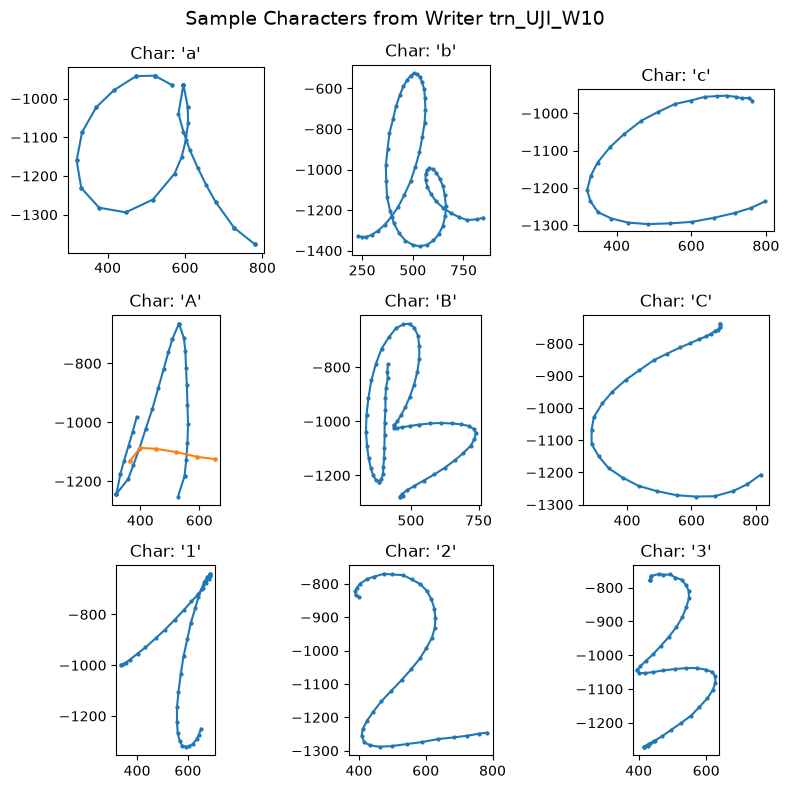

In [10]:
characters = ['a', 'b', 'c', 'A', 'B', 'C', '1', '2', '3']
writer = "trn_UJI_W10"

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for ax, char in zip(axes.flat, characters):
    strokes = data[writer][char][0]  # First repetition
    
    for stroke in strokes:
        xs = [p[0] for p in stroke]
        ys = [p[1] for p in stroke]
        ax.plot(xs, ys, "-o", markersize=2)
        
    ax.set_aspect("equal")
    ax.set_title(f"Char: '{char}'")

plt.suptitle(f"Sample Characters from Writer {writer}", fontsize=14)
plt.tight_layout()
plt.show()

In [11]:
#4: resampling


# =====================================================================
# STEP 1: Find the mean number of points for each character
# =====================================================================

# Get all unique characters in the dataset
all_chars = []
for writer_id in data:
    for char in data[writer_id]:
        if char not in all_chars:
            all_chars.append(char)

# Calculate the median for each character
char_targets = {}

for char in all_chars:
    point_counts = []
    
    # Collect point counts across all writers and repetitions
    for writer_id in data:
        if char in data[writer_id]:
            for rep in data[writer_id][char]:
                # Total points in this repetition
                total_pts = sum(len(stroke) for stroke in rep)
                point_counts.append(total_pts)
                
    # Compute the mean (rounded to integer)
    char_targets[char] = round(np.mean(point_counts))
    
# =====================================================================
# STEP 2: Resampling functions (Your algorithm)
# =====================================================================

def get_stroke_length(stroke):
    length = 0.0
    for i in range(len(stroke) - 1):
        dx = stroke[i + 1][0] - stroke[i][0]
        dy = stroke[i + 1][1] - stroke[i][1]
        length += (dx**2 + dy**2)**0.5
    return length

def resample_stroke(stroke, n_points):
    t_old = np.linspace(0, 1, len(stroke))
    t_new = np.linspace(0, 1, n_points)
    
    xs = [p[0] for p in stroke]
    ys = [p[1] for p in stroke]
    
    new_xs = np.interp(t_new, t_old, xs)
    new_ys = np.interp(t_new, t_old, ys)
    
    new_stroke = []
    for i in range(n_points):
        new_stroke.append((float(new_xs[i]), float(new_ys[i])))
    return new_stroke

def resample_character(strokes, target_points):
    lengths = [get_stroke_length(s) for s in strokes]
    total_length = sum(lengths)
    
    if total_length == 0:
        total_length = 1.0
        lengths = [1.0] * len(strokes)
        
    new_strokes = []
    # 1. Calculate points for each stroke
    pts = []
    for l in lengths:
        pts.append(max(2, int(round((l / total_length) * target_points))))

    # 2. Fix rounding difference by adding it to the longest stroke
    diff = target_points - sum(pts)
    longest_idx = lengths.index(max(lengths))
    pts[longest_idx] += diff

    # 3. Resample each stroke
    new_strokes = []
    for i in range(len(strokes)):
        new_strokes.append(resample_stroke(strokes[i], pts[i]))
        
    return new_strokes


# =====================================================================
# STEP 3: Create resampled_data using each character's median target
# =====================================================================
import copy
# 1. Make a copy of data with the exact same structure
resampled_data = copy.deepcopy(data)

# 2. Replace ONLY the (x, y) coordinates with the resampled version
print("Resampling coordinates... please wait...")

for writer_id in resampled_data:
    for char in resampled_data[writer_id]:
        # Target points from your calculated median
        target = char_targets[char]
        
        # Loop through repetitions (rep 0 and rep 1)
        for i in range(len(resampled_data[writer_id][char])):
            # Overwrite only the strokes (x, y points) of this repetition
            resampled_data[writer_id][char][i] = resample_character(resampled_data[writer_id][char][i], target_points=target)

print("Done! Only the (x, y) points have been updated.")


Resampling coordinates... please wait...
Done! Only the (x, y) points have been updated.


In [12]:
#2: centering the characters
def center_character(strokes):
    """
    Centers a character using bounding-box midpoint:
    1. Find min_x, max_x, min_y, max_y across all strokes.
    2. Compute center_x = (min_x + max_x) / 2 and center_y = (min_y + max_y) / 2.
    3. Subtract (center_x, center_y) from every point.
    """
    # Step 1: Collect all x and y coordinates from all strokes
    all_x = [p[0] for stroke in strokes for p in stroke]
    all_y = [p[1] for stroke in strokes for p in stroke]
    
    min_x, max_x = min(all_x), max(all_x)
    min_y, max_y = min(all_y), max(all_y)
    
    # Step 2: Calculate the center of x and y
    center_x = (min_x + max_x) / 2.0
    center_y = (min_y + max_y) / 2.0
    
    # Step 3: Subtract the center from all points
    centered_strokes = []
    for stroke in strokes:
        centered_stroke = [(x - center_x, y - center_y) for x, y in stroke]
        centered_strokes.append(centered_stroke)
        
    return centered_strokes

In [13]:
for writer_id, chars in resampled_data.items():
    for char, repetitions in chars.items():
        for rep_idx, rep in enumerate(repetitions):
            # Center this repetition
            repetitions[rep_idx] = center_character(rep)

print("All characters across all writers have been centered at (0, 0)!")

All characters across all writers have been centered at (0, 0)!


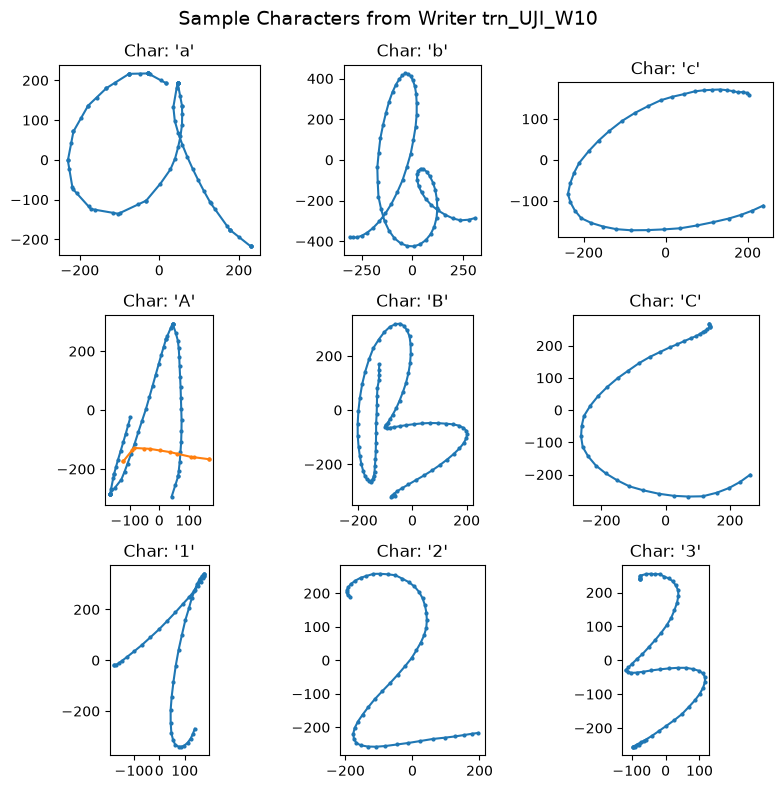

In [14]:
characters = ['a', 'b', 'c', 'A', 'B', 'C', '1', '2', '3']
writer = "trn_UJI_W10"

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for ax, char in zip(axes.flat, characters):
    strokes = resampled_data[writer][char][0]  # First repetition
    
    for stroke in strokes:
        xs = [p[0] for p in stroke]
        ys = [p[1] for p in stroke]
        ax.plot(xs, ys, "-o", markersize=2)
        
    ax.set_aspect("equal")
    ax.set_title(f"Char: '{char}'")

plt.suptitle(f"Sample Characters from Writer {writer}", fontsize=14)
plt.tight_layout()
plt.show()

In [15]:
# =====================================================================
# Test the length of all characters across the entire dataset
# =====================================================================

all_passed = True
total_samples_checked = 0

print("Testing character lengths across all writers...")
print("-" * 50)

# Check every character
for char in char_targets:
    target_len = char_targets[char]
    char_lengths = []
    
    # Collect lengths from all writers and repetitions
    for writer_id in resampled_data:
        if char in resampled_data[writer_id]:
            for rep in resampled_data[writer_id][char]:
                # Total points in this repetition
                pts_count = sum(len(stroke) for stroke in rep)
                char_lengths.append(pts_count)
                total_samples_checked += 1

    # Verify that all demonstrations of this character have the exact same length
    min_len = min(char_lengths)
    max_len = max(char_lengths)
    
    if not (min_len == max_len == target_len):        
        print(f"Mismatch in character '{char}': min={min_len}, max={max_len}, target={target_len}")
        all_passed = False

# Final Result
print("-" * 50)
if all_passed:
    print(f"SUCCESS! All {total_samples_checked} samples passed the test!")
    print("Every demonstration of the same character has the exact same length.")
else:
    print("Some characters had discrepancies.")

Testing character lengths across all writers...
--------------------------------------------------
--------------------------------------------------
SUCCESS! All 11640 samples passed the test!
Every demonstration of the same character has the exact same length.


In [16]:
# 5: relative displacement and pen state

#Convert absolute coordinates to relative displacements and pen state
def strokes_to_deltas(strokes):
    """
    Converts strokes into (dx, dy, pen_state).
    
    - If the first point is NOT (0, 0):
      Add an initial step from (0, 0) to the first point with pen UP (1).
    - If the first point IS (0, 0): start drawing directly (pen DOWN).
    
    pen_state:
      0 = Pen DOWN (drawing on paper)
      1 = Pen UP   (flying through the air)
    """
    PEN_DOWN, PEN_UP,END = 0, 1 , 2
    all_points = []
    end_indices = []
    
    for stroke in strokes:
        all_points.extend(stroke)
        end_indices.append(len(all_points) - 1)
        
    trajectory = []
    trajectory.append([0.0 , 0.0 , 1])
    
    # Check if the first point is already at (0, 0)
    first_x, first_y = all_points[0]
    
    if first_x != 0.0 or first_y != 0.0:
        # First point is NOT at (0, 0):
        # Add a pen UP step from (0, 0) to the first real point
        dx = first_x - 0.0
        dy = first_y - 0.0
        trajectory.append((float(dx), float(dy), PEN_UP))  # pen UP: flying to start
        
    # Now compute the rest of the displacements
    for i in range(1, len(all_points)):
        dx = all_points[i][0] - all_points[i - 1][0]
        dy = all_points[i][1] - all_points[i - 1][1]
        
        # Previous point was the end of a stroke -> pen UP (transition)
        pen_state = PEN_UP if (i - 1) in end_indices else PEN_DOWN
        
        trajectory.append((float(dx), float(dy), pen_state))
    trajectory.append((0,0,END))  # Add an END token at the end of the trajectory
  
    return trajectory

In [17]:
# Build delta_data (flat list per rep, no stroke nesting)
delta_data = {}

for writer_id in resampled_data:
    delta_data[writer_id] = {}
    
    for char in resampled_data[writer_id]:
        delta_data[writer_id][char] = []
        
        for rep in resampled_data[writer_id][char]:
            # rep is a list of strokes -> becomes a flat list of (dx, dy, pen_state)
            delta_rep = strokes_to_deltas(rep)
            delta_data[writer_id][char].append(delta_rep)


In [18]:
def deltas_to_strokes(trajectory):
    """
    Reconstructs (x, y) strokes from (dx, dy, pen_state).
    
    pen_state = 0: pen is DOWN (this step is part of a stroke -> draw it)
    pen_state = 1: pen is UP   (this step is an air move -> skip it)
    """
    strokes = []
    current_stroke = []
    
    x, y = 0.0, 0.0
    
    for dx, dy, pen_state in trajectory:
        prev_x, prev_y = x, y
        x = x + dx
        y = y + dy
        
        if pen_state == 0:
            # Pen is DOWN: include this step in the current stroke
            if not current_stroke:
                # First point of the stroke: include the "from" position too
                current_stroke.append((prev_x, prev_y))
            current_stroke.append((x, y))
            
        else:
            # Pen is UP: flying through the air
            # Save the stroke we were drawing (if any) and reset
            if current_stroke:
                strokes.append(current_stroke)
                current_stroke = []
                
    # Save the last stroke if it exists
    if current_stroke:
        strokes.append(current_stroke)        
    return strokes




Character 'a' has 1 strokes after reconstruction.
Character 'b' has 1 strokes after reconstruction.
Character 'c' has 1 strokes after reconstruction.
Character 'A' has 2 strokes after reconstruction.
Character 'B' has 1 strokes after reconstruction.
Character 'C' has 1 strokes after reconstruction.
Character '1' has 1 strokes after reconstruction.
Character '2' has 1 strokes after reconstruction.
Character '3' has 1 strokes after reconstruction.


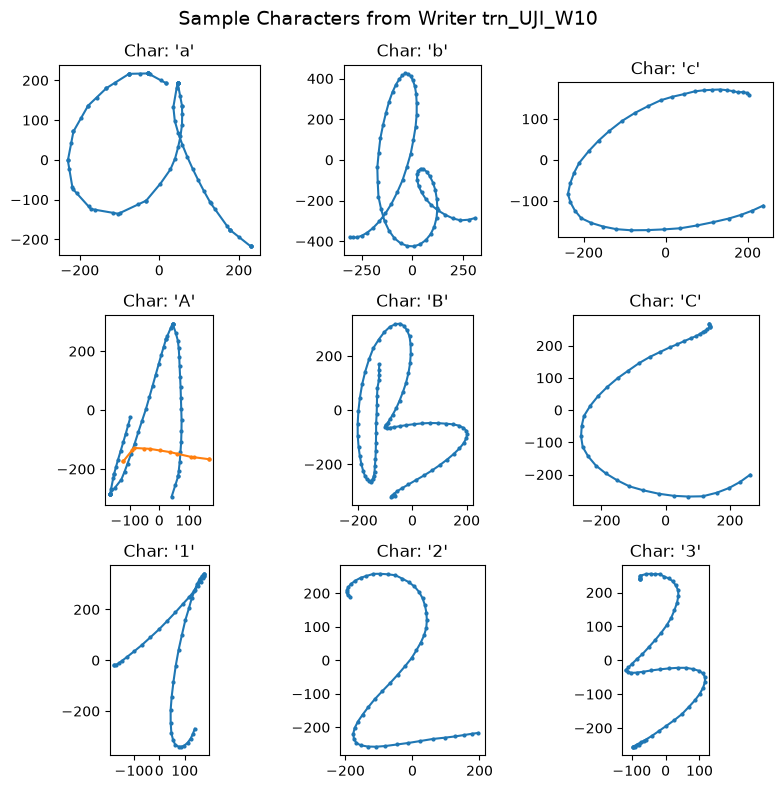

In [19]:
# Plot from delta_data
characters = ['a', 'b', 'c', 'A', 'B', 'C', '1', '2', '3']
writer = "trn_UJI_W10"

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for ax, char in zip(axes.flat, characters):
    # Get the flat trajectory from delta_data
    trajectory = delta_data[writer][char][0]
    
    # Reconstruct strokes from (dx, dy, pen_state)
    strokes = deltas_to_strokes(trajectory)
    print(f"Character '{char}' has {len(strokes)} strokes after reconstruction.")
    
    for stroke in strokes:
        xs = [p[0] for p in stroke]
        ys = [p[1] for p in stroke]
        ax.plot(xs, ys, "-o", markersize=2)
        
    ax.set_aspect("equal")
    ax.set_title(f"Char: '{char}'")

plt.suptitle(f"Sample Characters from Writer {writer}", fontsize=14)
plt.tight_layout()
plt.show()

In [20]:
# Check if reconstructed strokes from delta_data match original stroke count

all_passed = True
total_checked = 0
mismatches = []

for writer_id in resampled_data:
    for char in resampled_data[writer_id]:
        for rep_idx in range(len(resampled_data[writer_id][char])):
            
            # Original number of strokes
            original_strokes = resampled_data[writer_id][char][rep_idx]
            original_count = len(original_strokes)
            
            # Reconstruct strokes from delta_data
            trajectory = delta_data[writer_id][char][rep_idx]
            reconstructed_strokes = deltas_to_strokes(trajectory)
            reconstructed_count = len(reconstructed_strokes)
            
            total_checked += 1
            
            # Compare stroke counts
            if original_count != reconstructed_count:
                all_passed = False
                mismatches.append({
                    "writer": writer_id,
                    "char": char,
                    "rep": rep_idx,
                    "original": original_count,
                    "reconstructed": reconstructed_count
                })

# Print results
print(f"Total samples checked: {total_checked}")
print("-" * 50)

if all_passed:
    print("SUCCESS! All stroke counts match perfectly!")
else:
    print(f"FAILED! {len(mismatches)} mismatches found:")
    for m in mismatches[:10]:  # Show first 10 mismatches
        print(f"  Writer: {m['writer']} | Char: '{m['char']}' | Rep: {m['rep']} "
              f"| Original strokes: {m['original']} | Reconstructed: {m['reconstructed']}")

Total samples checked: 11640
--------------------------------------------------
SUCCESS! All stroke counts match perfectly!


In [21]:
# Check if reconstructed strokes and points from delta_data match original data

all_passed = True
total_checked = 0
mismatches = []

for writer_id in resampled_data:
    for char in resampled_data[writer_id]:
        for rep_idx in range(len(resampled_data[writer_id][char])):
            
            # Original strokes
            original_strokes = resampled_data[writer_id][char][rep_idx]
            original_stroke_count = len(original_strokes)
            
            # Reconstruct strokes from delta_data
            trajectory = delta_data[writer_id][char][rep_idx]
            reconstructed_strokes = deltas_to_strokes(trajectory)
            reconstructed_stroke_count = len(reconstructed_strokes)
            
            total_checked += 1
            
            # 1. Compare stroke counts
            if original_stroke_count != reconstructed_stroke_count:
                all_passed = False
                mismatches.append({
                    "type": "stroke_count",
                    "writer": writer_id,
                    "char": char,
                    "rep": rep_idx,
                    "original": original_stroke_count,
                    "reconstructed": reconstructed_stroke_count
                })
                continue
            
            # 2. Compare number of points per stroke
            stroke_mismatch = False
            for stroke_idx, (orig_stroke, recon_stroke) in enumerate(zip(original_strokes, reconstructed_strokes)):
                if len(orig_stroke) != len(recon_stroke):
                    all_passed = False
                    mismatches.append({
                        "type": "point_count",
                        "writer": writer_id,
                        "char": char,
                        "rep": rep_idx,
                        "stroke_idx": stroke_idx,
                        "original": len(orig_stroke),
                        "reconstructed": len(recon_stroke)
                    })
                    stroke_mismatch = True
                    break
            
            if stroke_mismatch:
                continue

# Print results
print(f"Total samples checked: {total_checked}")
print("-" * 50)

if all_passed:
    print("SUCCESS! All stroke counts and point counts match perfectly!")
else:
    print(f"FAILED! {len(mismatches)} mismatches found:")
    for m in mismatches[:10]:  # Show first 10 mismatches
        if m["type"] == "stroke_count":
            print(f"  [Stroke Count] Writer: {m['writer']} | Char: '{m['char']}' | Rep: {m['rep']} "
                  f"| Original: {m['original']} | Reconstructed: {m['reconstructed']}")
        else:
            print(f"  [Point Count]  Writer: {m['writer']} | Char: '{m['char']}' | Rep: {m['rep']} | Stroke: {m['stroke_idx']} "
                  f"| Original: {m['original']} points | Reconstructed: {m['reconstructed']} points")

Total samples checked: 11640
--------------------------------------------------
SUCCESS! All stroke counts and point counts match perfectly!


Scaling based on thev maximum

Passed: 11591 trajectories have maximum absolute delta = 1.
Empty or all-zero trajectories: 49


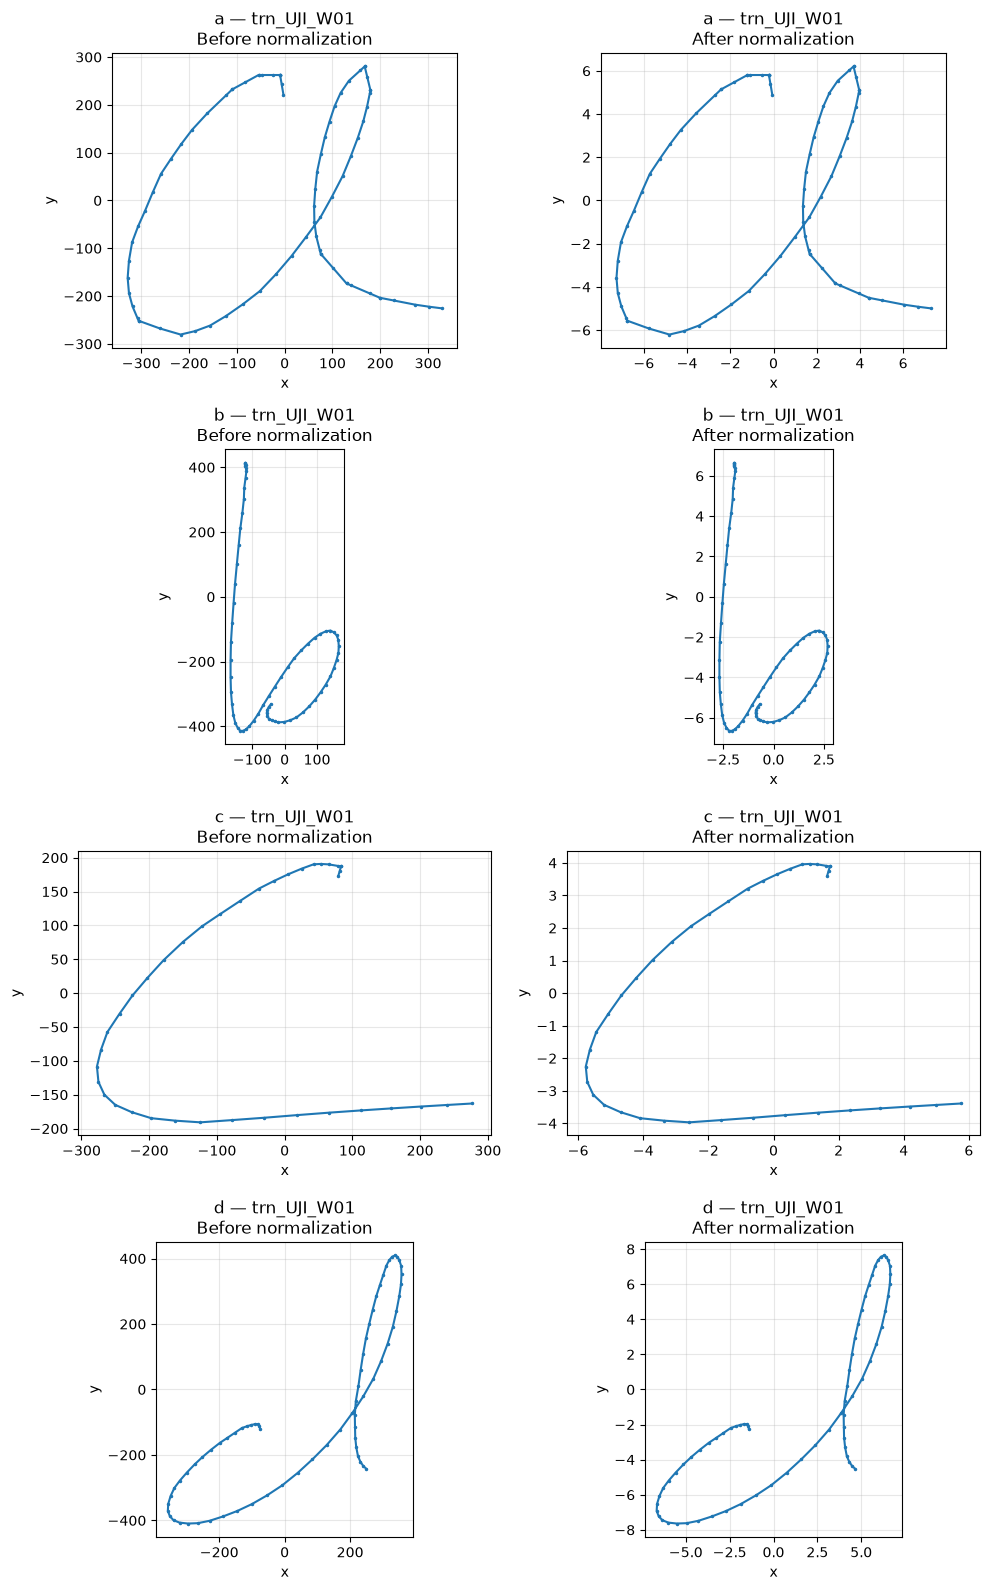

In [28]:
def resample_pen_up(dataset):
    result = {}

    for writer, chars in dataset.items():
        result[writer] = {}

        for char, repetitions in chars.items():
            result[writer][char] = []

            for trajectory in repetitions:
                drawing_steps = np.array([
                    (dx, dy)
                    for dx, dy, pen in trajectory
                    if pen == 0
                ], dtype=float)

                # Keep trajectories unchanged when no movement defines a scale.
                if drawing_steps.size == 0:
                    result[writer][char].append(list(trajectory))
                    continue

                avg_dx, avg_dy = np.mean(np.abs(drawing_steps), axis=0)
                avg_distance = np.mean(
                    np.linalg.norm(drawing_steps, axis=1)
                )

                if avg_distance == 0:
                    result[writer][char].append(list(trajectory))
                    continue

                # Fallback when drawing has no movement along one axis.
                step_x = avg_dx if avg_dx > 0 else avg_distance
                step_y = avg_dy if avg_dy > 0 else avg_distance

                new_trajectory = []

                for dx, dy, pen in trajectory:
                    if pen == 1:
                        n = max(1, int(np.ceil(max(
                            abs(dx) / step_x,
                            abs(dy) / step_y
                        ))))

                        new_trajectory.extend(
                            (float(dx / n), float(dy / n), pen)
                            for _ in range(n)
                        )
                    else:
                        new_trajectory.append((dx, dy, pen))

                result[writer][char].append(new_trajectory)

    return result


# Resample pen-up movements in the delta data.
delta_data_resampled = resample_pen_up(delta_data)


def scale_character_max(trajectory):
    """Scale dx and dy by their shared maximum absolute value."""
    scale = max(
        (max(abs(dx), abs(dy)) for dx, dy, _ in trajectory),
        default=0.0
    )
    scale = scale if scale > 0 else 1.0

    return [
        (dx / scale, dy / scale, pen)
        for dx, dy, pen in trajectory
    ]


delta_data_resampled_normalized_max = {
    writer: {
        char: [
            scale_character_max(trajectory)
            for trajectory in repetitions
        ]
        for char, repetitions in chars.items()
    }
    for writer, chars in delta_data_resampled.items()
}


checked = 0
zero_trajectories = 0

for writer, chars in delta_data_resampled_normalized_max.items():
    for char, repetitions in chars.items():
        for rep_idx, trajectory in enumerate(repetitions):
            maximum = max(
                (max(abs(dx), abs(dy)) for dx, dy, _ in trajectory),
                default=0.0
            )

            if maximum == 0:
                zero_trajectories += 1
                continue

            assert np.isclose(maximum, 1.0), (
                f"{writer}, {char}, repetition {rep_idx}: "
                f"maximum = {maximum}"
            )
            checked += 1

print(f"Passed: {checked} trajectories have maximum absolute delta = 1.")
print(f"Empty or all-zero trajectories: {zero_trajectories}")


def plot_before_after(before, after, n_examples=4):
    examples = [
        (writer, char)
        for writer, chars in before.items()
        for char, repetitions in chars.items()
        if repetitions
    ][:n_examples]

    if not examples:
        raise ValueError("No trajectories to plot.")

    fig, axes = plt.subplots(
        len(examples), 2,
        figsize=(10, 4 * len(examples)),
        squeeze=False
    )

    for row, (writer, char) in enumerate(examples):
        trajectories = [
            before[writer][char][0],
            after[writer][char][0]
        ]

        for col, trajectory in enumerate(trajectories):
            ax = axes[row, col]

            for stroke in deltas_to_strokes(trajectory):
                if len(stroke):
                    x, y = zip(*stroke)
                    ax.plot(x, y, ".-", markersize=3)

            title = "Before normalization" if col == 0 else "After normalization"
            ax.set_title(f"{char} — {writer}\n{title}")
            ax.set_xlabel("x")
            ax.set_ylabel("y")
            ax.set_aspect("equal", adjustable="box")
            ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


plot_before_after(
    delta_data_resampled,
    delta_data_resampled_normalized_max,
    n_examples=4
)



In [29]:
import pickle

# Save delta data
with open("delta_data_resampled_normalized_max.pkl", "wb") as file:
    pickle.dump(delta_data_resampled_normalized_max, file)

In [27]:
zero_chars = set()

for writer, chars in delta_data_resampled_normalized_max.items():
    for char, repetitions in chars.items():
        for rep_idx, trajectory in enumerate(repetitions):
            if not trajectory or all(
                dx == 0 and dy == 0
                for dx, dy, _ in trajectory
            ):
                zero_chars.add(char)
                print(
                    f"Character: {char!r} | Writer: {writer} | "
                    f"Repetition: {rep_idx}"
                )

print("Characters with empty or all-zero trajectories:", sorted(zero_chars))

Character: '.' | Writer: trn_UJI_W01 | Repetition: 1
Character: '.' | Writer: trn_UJI_W02 | Repetition: 1
Character: '.' | Writer: trn_UJI_W03 | Repetition: 1
Character: '.' | Writer: trn_UJI_W04 | Repetition: 1
Character: '.' | Writer: trn_UJI_W06 | Repetition: 0
Character: '.' | Writer: trn_UJI_W06 | Repetition: 1
Character: '.' | Writer: trn_UJI_W07 | Repetition: 0
Character: '.' | Writer: trn_UJI_W07 | Repetition: 1
Character: '.' | Writer: trn_UJI_W08 | Repetition: 0
Character: '.' | Writer: tst_UJI_W13 | Repetition: 1
Character: '.' | Writer: trn_UPV_W17 | Repetition: 0
Character: '.' | Writer: tst_UPV_W18 | Repetition: 0
Character: '.' | Writer: tst_UPV_W18 | Repetition: 1
Character: '.' | Writer: tst_UPV_W21 | Repetition: 1
Character: '.' | Writer: trn_UPV_W23 | Repetition: 0
Character: '.' | Writer: trn_UPV_W23 | Repetition: 1
Character: '.' | Writer: tst_UPV_W24 | Repetition: 0
Character: '.' | Writer: tst_UPV_W24 | Repetition: 1
Character: '.' | Writer: trn_UPV_W25 | Repetit

In [ ]:
### Task 2 : baseline method

#1: average trajectory for each character across all writers and repetitions

# =====================================================================
# STEP 1: Average of resampled_data  ->  avg_resampled[char] = (N, 2)
# =====================================================================
avg_resampled = {}

for char in char_targets:
    all_samples = []   # one (N, 2) array per demonstration

    for writer_id in resampled_data:
        if char in resampled_data[writer_id]:
            for rep in resampled_data[writer_id][char]:
                # Flatten the strokes into one list of (x, y) points
                points = []
                for stroke in rep:
                    points.extend(stroke)
                all_samples.append(np.array(points))

    # Mean over all demonstrations (axis 0) -> shape (N, 2)
    avg_resampled[char] = np.mean(all_samples, axis=0)

print("avg_resampled done:", len(avg_resampled), "characters")
# =====================================================================
# STEP 2: Average of delta_data  ->  avg_delta[char] = (T, 3)  (dx, dy, pen)
# =====================================================================
avg_delta = {}

for char in char_targets:
    all_samples = []   # one (T, 3) array per demonstration

    for writer_id in delta_data:
        if char in delta_data[writer_id]:
            for rep in delta_data[writer_id][char]:
                all_samples.append(np.array(rep))

    # Safety check: keep only samples with the most common length
    lengths = [len(s) for s in all_samples]
    target_len = max(set(lengths), key=lengths.count)
    good_samples = [s for s in all_samples if len(s) == target_len]

    if len(good_samples) != len(all_samples):
        print(f"Char '{char}': skipped {len(all_samples) - len(good_samples)} samples with a different length")

    # Mean of dx, dy, and pen_state
    mean_traj = np.mean(good_samples, axis=0)

    # Pen state is 0 or 1, so the mean is a probability -> majority vote
    mean_traj[:, 2] = np.where(mean_traj[:, 2] >= 0.5, 1, 0)

    avg_delta[char] = mean_traj

print("avg_delta done:", len(avg_delta), "characters")


In [ ]:
# =====================================================================
# STEP 4: Plot the average trajectories (delta version)
# =====================================================================
characters = ['a', 'b', 'c', 'A', 'B', 'C', '1', '2', '3','F']

fig, axes = plt.subplots(2, 5, figsize=(8, 8))

for ax, char in zip(axes.flat, characters):
    strokes = avg_resampled[char]  # Use avg_resampled for plotting
    print(f"Character '{char}' has {len(strokes)} points in the average trajectory.")
    xs = strokes[:, 0]
    ys = strokes[:, 1]
    ax.plot(xs, ys, "-o", markersize=2)

    ax.set_title(f"Mean '{char}'")

plt.suptitle("Average trajectories", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# =====================================================================
# STEP 4: Plot the average trajectories (delta version)
# =====================================================================
characters = ['a', 'b', 'c', 'A', 'B', 'C', '1', '2', '3']

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for ax, char in zip(axes.flat, characters):
    strokes = deltas_to_strokes(avg_delta[char])

    for stroke in strokes:
        xs = [p[0] for p in stroke]
        ys = [p[1] for p in stroke]
        ax.plot(xs, ys, "-o", markersize=2)

    ax.set_aspect("equal")
    ax.set_title(f"Mean '{char}'")

plt.suptitle("Average trajectories", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
num_chars = len(char_targets)
num_writers = len(delta_data)
num_repetitions = len(delta_data['trn_UJI_W01']['F'])
# Pre-allocate a 2D matrix of shape (len(char_targets), len(delta_data))
absolute_error = np.zeros((num_chars, num_writers , num_repetitions))

i = 0 # char index


for char in char_targets:    
    # Loop through all writers and repetitions
    j = 0 # writer index
    for writer_id_test in delta_data:
        error_X = 0
        error_Y = 0
        for writer_id in delta_data:
            if writer_id_test != writer_id:                
                # Compute absolute error for each point
                for h in range(len(delta_data[writer_id_test][char])):
                    for q in range(min(len(delta_data[writer_id_test][char][h]), len(delta_data[writer_id][char][h]))):
                        error_X += np.abs(float(delta_data[writer_id_test][char][h][q][0]) - float(delta_data[writer_id][char][h][q][0]))
                        error_Y += np.abs(float(delta_data[writer_id_test][char][h][q][1]) - float(delta_data[writer_id][char][h][q][1]))
                    error = np.sqrt(error_X**2 + error_Y**2)
                    absolute_error[i][j][h] = error 

        j+=1
    i+=1

In [ ]:
best_per_char = {}
i = 0 # char index

for char in char_targets:
    min_error = 1e18
    best_writer = None
    best_rep = None
    j = 0 # writer index
    for writer_id in delta_data:
        for h in range(len(delta_data[writer_id][char])):
            if absolute_error[i][j][h] < min_error:
                min_error = absolute_error[i][j][h]
                best_writer = writer_id
                best_rep = h
        j+=1
    best_per_char[char] = delta_data[best_writer][char][best_rep]
    print(char, best_writer, best_rep, min_error)
    i+=1

In [ ]:
characters = ['a', 'b', 'c', 'A', 'B', 'C', '1', '2', '3']

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for ax, char in zip(axes.flat, characters):
    trajectory = best_per_char[char]

    strokes = deltas_to_strokes(trajectory)

    for stroke in strokes:
        xs = [p[0] for p in stroke]
        ys = [p[1] for p in stroke]
        ax.plot(xs, ys, "-o", markersize=2)

    ax.set_aspect("equal")
    ax.set_title(f"Char: '{char}'")

plt.suptitle("Lowest error sample per character", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:
# check the number of repetitions for each character across all writers
for char in char_targets:    
    # Loop through all writers and repetitions
    j = 0 # writer index
    for writer_id_test in delta_data:
        error_X = 0
        error_Y = 0
        for writer_id in delta_data:               
                # Compute absolute error for each point
            if len(delta_data[writer_id_test][char]) > 2:
                print("cor")
                break

In [ ]:
num_chars = len(char_targets)
num_writers = len(delta_data)
num_repetitions = len(delta_data['trn_UJI_W01']['F'])
# Pre-allocate a 2D matrix of shape (len(char_targets), len(delta_data))
absolute_error = np.zeros((num_chars, num_writers , num_repetitions))
i = 0 # char index


for char in char_targets:    
    # Loop through all writers and repetitions
    j = 0 # writer index
    for writer_id_test in delta_data:
        error_X = 0
        error_Y = 0
        for writer_id in delta_data:               
                # Compute absolute error for each point
            for h in range(len(delta_data[writer_id_test][char])):
                    if writer_id_test != writer_id:
                        for q in range(min(len(delta_data[writer_id_test][char][h]), len(delta_data[writer_id][char][h]))):

                            error_X += np.abs(float(delta_data[writer_id_test][char][h][q][0]) - float(delta_data[writer_id][char][h][q][0]))
                            error_Y += np.abs(float(delta_data[writer_id_test][char][h][q][1]) - float(delta_data[writer_id][char][h][q][1]))
                    else:
                        k = 1 - h  # If h is 0, k is 1; if h is 1, k is 0
                        for q in range(min(len(delta_data[writer_id_test][char][h]), len(delta_data[writer_id][char][k]))):

                            error_X += np.abs(float(delta_data[writer_id_test][char][h][q][0]) - float(delta_data[writer_id][char][k][q][0]))
                            error_Y += np.abs(float(delta_data[writer_id_test][char][h][q][1]) - float(delta_data[writer_id][char][k][q][1]))
                    error = np.sqrt(error_X**2 + error_Y**2)
                    absolute_error[i][j][h] = error 

        j+=1
    i+=1


In [ ]:
best_trajectories = {}
i = 0  # char index

for char in char_targets:
    min_error = float('inf')
    best_writer = None
    best_rep = None
    j = 0  # writer index

    for writer_id in delta_data:
        for h in range(len(delta_data[writer_id][char])):
            if absolute_error[i][j][h] < min_error:
                min_error = absolute_error[i][j][h]
                best_writer = writer_id
                best_rep = h
        j += 1

    best_trajectories[char] = delta_data[best_writer][char][best_rep]
    i += 1

In [ ]:
characters = ['a', 'b', 'c', 'A', 'B', 'C', '1', '2','$']

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for ax, char in zip(axes.flat, characters):
    trajectory = best_trajectories[char]
    strokes = deltas_to_strokes(trajectory)

    for stroke in strokes:
        xs = [p[0] for p in stroke]
        ys = [p[1] for p in stroke]
        ax.plot(xs, ys, "-o", markersize=2)

    ax.set_aspect("equal")
    ax.set_title(f"Char: '{char}'")

plt.suptitle("Lowest error sample per character", fontsize=14)
plt.tight_layout()
plt.show()

In [ ]:


# Save averaged trajectories
with open("averaged_trajectories.pkl", "wb") as file:
    pickle.dump(avg_delta, file)

# # Save best repetition for each character
with open("best_trajectories.pkl", "wb") as file:
    pickle.dump(best_trajectories, file)